In [1]:
# Cell 1 — Imports and paths

import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from torch_geometric.nn import GCNConv

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BASE_DIR = Path("D:/adaptive_federated_gnn")

GRAPH_FILE = BASE_DIR / "data/processed/edge_graph.pt"
CLIENT_FILE = BASE_DIR / "outputs/day10/federated_clients.pt"
GLOBAL_MODEL_FILE = BASE_DIR / "outputs/day12/global_model_round1.pt"

DAY13_OUTPUT = BASE_DIR / "outputs/day13"
DAY13_OUTPUT.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Output directory:", DAY13_OUTPUT)
print("Graph file exists:", GRAPH_FILE.exists())
print("Client file exists:", CLIENT_FILE.exists())
print("Global model exists:", GLOBAL_MODEL_FILE.exists())

c:\Users\daksh\anaconda3\envs\adaptive_gnn\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu
Output directory: D:\adaptive_federated_gnn\outputs\day13
Graph file exists: True
Client file exists: True
Global model exists: True


In [2]:
# Cell 2 — Load graph and inspect available fields

graph_data = torch.load(
    GRAPH_FILE,
    map_location="cpu",
    weights_only=False
)

clients = torch.load(
    CLIENT_FILE,
    map_location="cpu",
    weights_only=False
)

print("Graph keys:", list(graph_data.keys()))

for key, value in graph_data.items():
    if isinstance(value, torch.Tensor):
        print(key, "shape:", tuple(value.shape))

print("\nClient names:", list(clients.keys()))

Graph keys: ['edge_index', 'edge_attr', 'edge_label']
edge_index shape: (2, 286095)
edge_attr shape: (286095, 67)
edge_label shape: (286095,)

Client names: ['client_1', 'client_2', 'client_3']


In [4]:
# Cell 3 — Identify graph tensors

edge_index = graph_data["edge_index"].long()

# Detect feature key
feature_key = next(
    (
        key for key in ["edge_features", "edge_attr"]
        if key in graph_data
    ),
    None
)

# Detect label key — your graph uses edge_label
label_key = next(
    (
        key for key in [
            "edge_labels",
            "edge_label",
            "edge_y",
            "y"
        ]
        if key in graph_data
    ),
    None
)

if feature_key is None or label_key is None:
    raise KeyError(
        f"Could not find graph features or labels. "
        f"Available keys: {list(graph_data.keys())}"
    )

edge_features = graph_data[feature_key].float()
edge_labels = graph_data[label_key].long().view(-1)

num_nodes = int(edge_index.max().item()) + 1
edge_feature_size = edge_features.shape[1]
num_edges = edge_index.shape[1]

assert edge_features.shape[0] == num_edges, (
    "Edge feature count does not match edge count."
)

assert edge_labels.shape[0] == num_edges, (
    "Edge label count does not match edge count."
)

print("Nodes:", num_nodes)
print("Edges:", num_edges)
print("Feature size:", edge_feature_size)
print("Labels shape:", edge_labels.shape)
print("Label distribution:", torch.bincount(edge_labels))

Nodes: 4404
Edges: 286095
Feature size: 67
Labels shape: torch.Size([286095])
Label distribution: tensor([127291, 158804])


In [5]:
# Cell 4 — Recover training indices and create test indices

train_indices_list = []

for client_name, client_data in clients.items():

    indices = (
        client_data["local_edge_indices"]
        .long()
        .view(-1)
    )

    train_indices_list.append(indices)

train_indices = torch.cat(train_indices_list).unique()

assert train_indices.min().item() >= 0
assert train_indices.max().item() < num_edges

all_indices = torch.arange(num_edges)

is_training = torch.zeros(
    num_edges,
    dtype=torch.bool
)

is_training[train_indices] = True

test_indices = all_indices[~is_training]

assert len(test_indices) > 0

print("Training edges:", len(train_indices))
print("Held-out test edges:", len(test_indices))
print("Total edges:", len(train_indices) + len(test_indices))

Training edges: 200266
Held-out test edges: 85829
Total edges: 286095


In [6]:
# Cell 5 — Define EdgeGCN

class EdgeGCN(nn.Module):

    def __init__(
        self,
        num_nodes,
        edge_feature_size,
        embedding_size=16,
        hidden_size=32
    ):
        super().__init__()

        self.node_embeddings = nn.Embedding(
            num_nodes,
            embedding_size
        )

        self.conv1 = GCNConv(
            embedding_size,
            hidden_size
        )

        self.conv2 = GCNConv(
            hidden_size,
            hidden_size
        )

        self.classifier = nn.Sequential(
            nn.Linear(
                hidden_size * 2 + edge_feature_size,
                64
            ),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, edge_index, edge_features):

        node_ids = torch.arange(
            self.node_embeddings.num_embeddings,
            device=edge_index.device
        )

        x = self.node_embeddings(node_ids)

        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))

        source_embeddings = x[edge_index[0]]
        destination_embeddings = x[edge_index[1]]

        combined = torch.cat(
            [
                source_embeddings,
                destination_embeddings,
                edge_features
            ],
            dim=1
        )

        return self.classifier(combined)


print("EdgeGCN architecture defined.")

EdgeGCN architecture defined.


In [7]:
# Cell 6 — Load Day 12 global model

global_model = EdgeGCN(
    num_nodes=num_nodes,
    edge_feature_size=edge_feature_size
)

state_dict = torch.load(
    GLOBAL_MODEL_FILE,
    map_location="cpu",
    weights_only=True
)

global_model.load_state_dict(state_dict)
global_model = global_model.to(DEVICE)
global_model.eval()

print("Global model loaded successfully.")

Global model loaded successfully.


In [8]:
# Cell 7 — Global model inference

edge_index_device = edge_index.to(DEVICE)
features_device = edge_features.to(DEVICE)

with torch.no_grad():

    logits = global_model(
        edge_index_device,
        features_device
    )

    probabilities = torch.softmax(logits, dim=1)

    predictions = torch.argmax(
        probabilities,
        dim=1
    )

# Select only held-out test edges
test_indices_device = test_indices.to(DEVICE)

y_true = edge_labels[test_indices].numpy()

y_pred = (
    predictions[test_indices_device]
    .cpu()
    .numpy()
)

y_probability = (
    probabilities[test_indices_device, 1]
    .cpu()
    .numpy()
)

print("Test predictions:", len(y_pred))
print("Actual test labels:", len(y_true))
print("Inference completed.")

Test predictions: 85829
Actual test labels: 85829
Inference completed.


In [9]:
# Cell 8 — Calculate test metrics

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, zero_division=0
)

recall = recall_score(
    y_true, y_pred, zero_division=0
)

f1 = f1_score(
    y_true, y_pred, zero_division=0
)

if len(np.unique(y_true)) == 2:
    roc_auc = roc_auc_score(y_true, y_probability)
    pr_auc = average_precision_score(y_true, y_probability)
else:
    roc_auc = float("nan")
    pr_auc = float("nan")

metrics_df = pd.DataFrame([{
    "model": "FedAvg Global EdgeGCN",
    "test_edges": len(y_true),
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "roc_auc": roc_auc,
    "pr_auc": pr_auc
}])

display(metrics_df)

metrics_df.to_csv(
    DAY13_OUTPUT / "global_model_test_metrics.csv",
    index=False
)

print("Metrics saved.")

,model,test_edges,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,FedAvg Global EdgeGCN,85829,0.902352,0.851628,0.997943,0.918998,0.989,0.981877


Metrics saved.


Confusion matrix:
[[29905  8283]
 [   98 47543]]


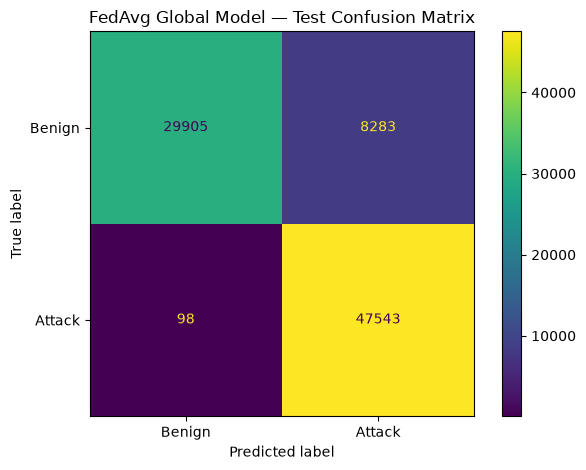

,TN,FP,FN,TP
0,29905,8283,98,47543


In [10]:
# Cell 9 — Plot and save confusion matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

print("Confusion matrix:")
print(cm)

display_obj = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Attack"]
)

display_obj.plot(values_format="d")
plt.title("FedAvg Global Model — Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    DAY13_OUTPUT / "global_confusion_matrix.png",
    dpi=150
)

plt.show()

tn, fp, fn, tp = cm.ravel()

confusion_df = pd.DataFrame([{
    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp)
}])

confusion_df.to_csv(
    DAY13_OUTPUT / "global_confusion_matrix.csv",
    index=False
)

display(confusion_df)

In [11]:
# Cell 10 — Detailed classification report

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Attack"],
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

display(report_df)

report_df.to_csv(
    DAY13_OUTPUT / "classification_report.csv"
)

,precision,recall,f1-score,support
Benign,0.996734,0.783099,0.877095,38188.000000
Attack,0.851628,0.997943,0.918998,47641.000000
accuracy,0.902352,0.902352,0.902352,0.902352
macro avg,0.924181,0.890521,0.898047,85829.000000
weighted avg,0.916190,0.902352,0.900354,85829.000000


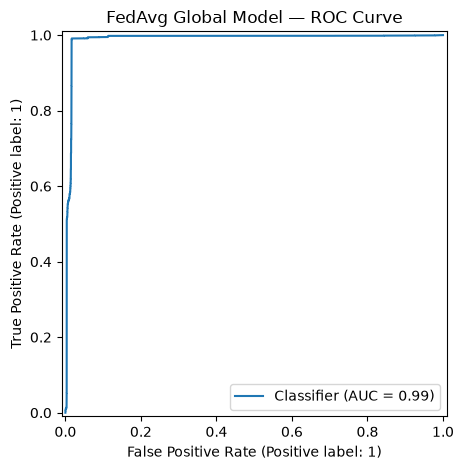

In [12]:
# Cell 11 — Plot ROC curve

if len(np.unique(y_true)) == 2:

    RocCurveDisplay.from_predictions(
        y_true,
        y_probability
    )

    plt.title("FedAvg Global Model — ROC Curve")
    plt.tight_layout()

    plt.savefig(
        DAY13_OUTPUT / "roc_curve.png",
        dpi=150
    )

    plt.show()

else:
    print("ROC curve requires both classes in the test set.")

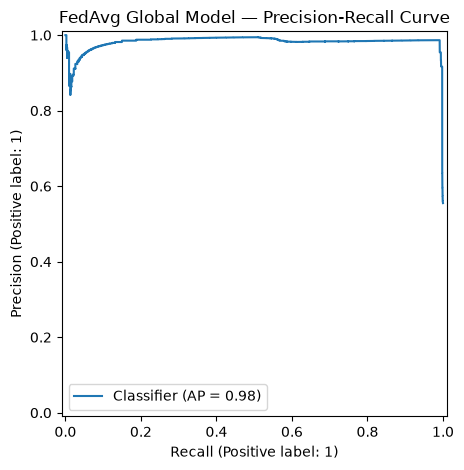

In [13]:
# Cell 12 — Plot Precision-Recall curve

if len(np.unique(y_true)) == 2:

    PrecisionRecallDisplay.from_predictions(
        y_true,
        y_probability
    )

    plt.title("FedAvg Global Model — Precision-Recall Curve")
    plt.tight_layout()

    plt.savefig(
        DAY13_OUTPUT / "precision_recall_curve.png",
        dpi=150
    )

    plt.show()

else:
    print("Precision-Recall curve requires both classes in the test set.")

In [14]:
# Cell 13 — Export individual test predictions

predictions_df = pd.DataFrame({
    "edge_index": test_indices.numpy(),
    "actual_label": y_true,
    "predicted_label": y_pred,
    "attack_probability": y_probability
})

predictions_df.to_csv(
    DAY13_OUTPUT / "global_test_predictions.csv",
    index=False
)

display(predictions_df.head(10))

print("Test predictions saved.")

,edge_index,actual_label,predicted_label,attack_probability
0,2,0,0,0.483114
1,5,0,0,0.482780
2,14,0,1,0.502742
3,15,0,1,0.522635
4,16,0,0,0.473800
5,18,0,0,0.469074
6,20,0,0,0.389598
7,22,0,0,0.473109
8,26,0,1,0.505297
9,28,0,0,0.284302


Test predictions saved.


In [15]:
# Cell 14 — Day 13 completion check

required_files = [
    "global_model_test_metrics.csv",
    "global_confusion_matrix.csv",
    "global_confusion_matrix.png",
    "classification_report.csv",
    "roc_curve.png",
    "precision_recall_curve.png",
    "global_test_predictions.csv"
]

print("=" * 55)
print("DAY 13 — FEDERATED EVALUATION")
print("=" * 55)

for filename in required_files:

    path = DAY13_OUTPUT / filename

    print(
        filename,
        "->",
        "OK" if path.exists() else "MISSING"
    )

print("\nFinal metrics:")
display(metrics_df)

DAY 13 — FEDERATED EVALUATION
global_model_test_metrics.csv -> OK
global_confusion_matrix.csv -> OK
global_confusion_matrix.png -> OK
classification_report.csv -> OK
roc_curve.png -> OK
precision_recall_curve.png -> OK
global_test_predictions.csv -> OK

Final metrics:


,model,test_edges,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,FedAvg Global EdgeGCN,85829,0.902352,0.851628,0.997943,0.918998,0.989,0.981877
